# Carga de Librerias

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score,cross_validate
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from scipy import stats
from sklearn.decomposition import PCA
import statsmodels.api as sm


# Limpieza de Datos

Se realiza una limpieza de datos para ajustar el dataset al objetivo del análisis. Solo se consideran los proyectos terminados, porque son los que deberían tener registrada tanto la fecha de inicio como la de término. Con esas dos fechas se construye la variable objetivo *Duracion_obra*. Además, se unifica la cantidad de viviendas: según el tipo de proyecto, este dato aparece repartido en dos columnas, así que se combina en una sola variable. Se realiza la misma accion con los montos de contrato, sin ebargo acá se utiliza el monto promedio de asignación de subsidio para rellenar 7 datos que quedan vacios.

Por otro lado, se filtran los proyectos que a pesar de tener un estado "Terminado" no cuentan con fecha de inicio y/o término, ya que estos son errores de registros que se deben corregir en sistema, sin embargo, esto se escapa del alcanze de este estudio.

In [26]:
class LimpiadorTrazabilidad:
    """Carga y limpia la base de trazabilidad para modelar la duración de obra."""

    COLUMNAS = {
        "PROGRAMA": "Programa",
        "CÓDIGO PROYECTO": "Codigo_proyecto",
        "NOMBRE PROYECTO": "Nombre_proyecto",
        "COMUNA": "Comuna",
        "NOMBRE PRESTADOR ASISTENCIA TÉCNICA": "Nombre_ep",
        "TIPOLOGÍA DEL PROYECTO": "Tipologia",
        "AÑO DE LLAMADO": "Ano_llamado",
        "Nº TOTAL DE FAMILIAS": "Viviendas_1",
        "Nº DE VIVIENDAS": "Viviendas_2",
        "MONTO TOTAL CONTRATO E.C. UF": "Monto_contrato",
        "MONTO UF TOTAL PROYECTO": "Monto_contrato_2",  
        "NOMBRE E.C. 5": "Nombre_constructora",
        "FECHA INICIO DE OBRA REAL  ENTREGA TERRENO": "Fecha_inicio",
        "ESTADO DEL PROYECTO": "Estado",
        "FECHA RECEPCIÓN FINAL DE OBRAS POR SERVIU": "Fecha_final_serviu",
        "FECHA RECEPCIÓN MUNICIPAL": "Fecha_final_dom",
    }
    CATEGORICAS = ["Comuna", "Nombre_ep", "Tipologia", "Nombre_constructora"]
    FORMATO_FECHA = "%d/%m/%Y"

    def __init__(self, ruta, programa="FSV", estado="Terminado"):
        self.ruta = ruta
        self.programa = programa
        self.estado = estado
        self.df = None
        self.registro = []   

    # utilidades
    def _registrar(self, paso):
        self.registro.append((paso, len(self.df)))

    @staticmethod
    def _a_numero(col):
        return pd.to_numeric(
            col.astype(str).str.strip().str.replace(",", ".", regex=False),
            errors="coerce",
        )

    def _a_fecha(self, col):
        return pd.to_datetime(col, format=self.FORMATO_FECHA, errors="coerce")

    # pasos
    def cargar(self):
        self.df = pd.read_csv(self.ruta, sep=";", encoding="latin-1", dtype=str)
        self.df = self.df[list(self.COLUMNAS)].rename(columns=self.COLUMNAS)
        self._registrar("cargar")
        return self

    def filtrar(self):
        self.df = self.df[
            (self.df["Estado"] == self.estado) & (self.df["Programa"] == self.programa)
        ].drop(columns=["Estado", "Programa"])
        self._registrar("filtrar")
        return self

    def unificar_viviendas(self):
        v1 = self.df["Viviendas_1"]
        no_aplica = v1.astype(str).str.strip().str.upper() == "NO APLICA"
        self.df["Viviendas"] = v1.mask(no_aplica, self.df["Viviendas_2"])
        self.df = self.df.drop(columns=["Viviendas_1", "Viviendas_2"])
        return self

    def unificar_montos(self):
        m1 = self._a_numero(self.df["Monto_contrato"])
        m2 = self._a_numero(self.df["Monto_contrato_2"])
        monto = m1.mask(m1 == 0, m2)
        self.df["Monto"] = monto.where(monto > 0)
        self.df = self.df.drop(columns=["Monto_contrato", "Monto_contrato_2"])
        return self

    def construir_duracion(self):
        inicio = self._a_fecha(self.df["Fecha_inicio"])
        termino = self._a_fecha(self.df["Fecha_final_dom"]).fillna(
            self._a_fecha(self.df["Fecha_final_serviu"])
        )
        self.df["Duracion_obra"] = (termino - inicio).dt.days
        self.df = self.df.dropna(subset=["Duracion_obra"]).drop(
            columns=["Fecha_inicio", "Fecha_final_dom", "Fecha_final_serviu"]
        )
        self._registrar("construir_duracion")
        return self

    def tipificar(self):
        for col in ["Ano_llamado", "Viviendas", "Duracion_obra"]:
            self.df[col] = pd.to_numeric(self.df[col], errors="coerce").astype("Int64")
        for col in self.CATEGORICAS:
            self.df[col] = self.df[col].str.strip().replace("", pd.NA).astype("category")
        return self

    # ejecución
    def ejecutar(self):
        (self.cargar()
             .filtrar()
             .unificar_viviendas()
             .unificar_montos()
             .construir_duracion()
             .tipificar())
        self.df = self.df.reset_index(drop=True)
        return self.df


In [27]:
#Ejecuto Limpieza de Datos
ruta = r"C:\Users\ggalvezb\OneDrive - Ministerio de Vivienda y Urbanismo\Curso BigData\Trabajo Final\Datos\trazabilidad.csv"

limpiador = LimpiadorTrazabilidad(ruta)
trazabilidad = limpiador.ejecutar()


print(limpiador.registro) 


[('cargar', 2733), ('filtrar', 1034), ('construir_duracion', 934)]


Se realiza la limpieza del Dataset

# Analisis Estadistico de Datos

In [28]:
trazabilidad.shape    

(934, 10)

EL data set limpio contiene 934 observaciones y 10 variables de medición

In [29]:
# Se observan las 5 primeras filas del dataset
trazabilidad.head()


,Codigo_proyecto,Nombre_proyecto,Comuna,Nombre_ep,Tipologia,Ano_llamado,Nombre_constructora,Viviendas,Monto,Duracion_obra
0,10171,ROBINSON ROJAS,RENCA,CENOHABIT LIMITADA,Construcción de Viviendas en Sitio Propio,2008,CONSTRUCTORA ARTUS Y ARTUS LIMITADA,19,7220.0,434
1,10226,TECNOINGENIERIA JOSE CALDERON II,PAINE,Sociedad Tecnoingenieria Limitada,Construcción en Nuevos Terrenos,2008,CONSTRUCTORA GPR S.A.,110,57046.0,325
2,1023,ETAPA II COMITE HABITACIONAL JUNTA DE VECINOS ...,PAINE,SOCIEDAD INMOBILIARIA ARCAMERI LIMITADA,Construcción de Viviendas en Sitio Propio,2006,CONSTRUCTORA E INMOBILIARIA G L G LIMITADA,33,11385.0,369
3,102722,LISZT 3066,SAN JOAQUIN,Inmobiliaria Prohogar SA Región Metropolitana,Construcción en Nuevos Terrenos,2011,CONSTRUCTORA NOVAL LIMITADA,36,30600.0,602
4,103416,BRASIL IV,SAN JOAQUIN,Inmobiliaria Prohogar SA Región Metropolitana,Construcción en Nuevos Terrenos,2011,CONSTRUCTORA NOVAL LIMITADA,40,34000.0,606


In [30]:
# Resumen de la información

print("\nInformación del dataframe:")
print(trazabilidad.info())


Información del dataframe:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 934 entries, 0 to 933
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Codigo_proyecto      934 non-null    object  
 1   Nombre_proyecto      934 non-null    object  
 2   Comuna               934 non-null    category
 3   Nombre_ep            934 non-null    category
 4   Tipologia            934 non-null    category
 5   Ano_llamado          920 non-null    Int64   
 6   Nombre_constructora  668 non-null    category
 7   Viviendas            934 non-null    Int64   
 8   Monto                927 non-null    float64 
 9   Duracion_obra        934 non-null    Int64   
dtypes: Int64(3), category(4), float64(1), object(2)
memory usage: 63.1+ KB
None


In [31]:
# Proporción de valores nulos por Variable

null_percentage = trazabilidad.isnull().mean() * 100
print("\nPorcentaje de valores nulos en cada variable:")
print(null_percentage)


Porcentaje de valores nulos en cada variable:
Codigo_proyecto         0.000000
Nombre_proyecto         0.000000
Comuna                  0.000000
Nombre_ep               0.000000
Tipologia               0.000000
Ano_llamado             1.498929
Nombre_constructora    28.479657
Viviendas               0.000000
Monto                   0.749465
Duracion_obra           0.000000
dtype: float64


El porcentaje de valores nuloes de "Nombre_constructora" contine un valor significativo para el análisis, sin embargo si filtramos las observaciones que no contengan constructora se va a ver muy disminuido el número total de observaciones, lo que afectará fuertemente al modelo. Por lo tanto se decide dejar estos valores como "Otro". La variable Monto se decide rellenar con el valor promedio de un subsidio y la Variables Año de Llamado se decide dejar tal cual, debido a que este valor probablemente no se use en el modelo.

In [32]:
#reemplazo los nulos de Nombre_constructora por "Otro"
trazabilidad["Nombre_constructora"] = (
    trazabilidad["Nombre_constructora"].cat.add_categories("Otro").fillna("Otro")
)

In [33]:
#Relleno valor de Monto
trazabilidad["Monto"] = (
    trazabilidad["Monto"].fillna(726)
)

In [34]:
# Identificación y división de variables numéricas y categóricas
categorical_vars = ["Comuna","Nombre_ep","Tipologia","Nombre_constructora"]
numeric_vars = ["Viviendas","Monto","Duracion_obra"]

c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


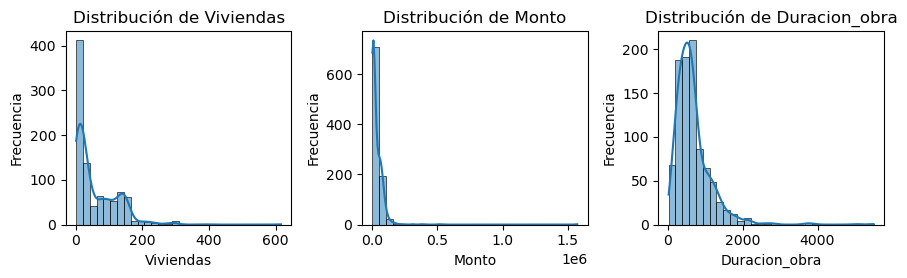

In [35]:
# Visualización de Distribuciones de Variables Numéricas
plt.figure(figsize=(12, 10))
for i, var in enumerate(numeric_vars):
    plt.subplot(4, 4, i + 1)
    sns.histplot(trazabilidad[var], bins=30, kde=True)
    plt.title(f'Distribución de {var}')
    plt.xlabel(var)
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

Las tres variables tienen un sesgo a la derecha, esto pesa bastante en una regresión:
* Viviendas: se ven dos grupos, esto se debe a las ditintas tipologias de los proyectos.
* Monto: Acá se debe revisar si existen valores extremos debido a una mezcla de Pesos con UF o por algún error de tipeo
* Duración de Obra: A pesar de que se ven obras que superan los 5.000 días (15 años) estos casos si son factibles, debido a que hubieron proyectos con paralizaciones extremas y reiterados quiebres de constructoras.

In [36]:
#Reviso outliers de la columna Monto
col = "Monto"
q1 = trazabilidad[col].quantile(0.25)
q3 = trazabilidad[col].quantile(0.75)
iqr = q3 - q1

lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

outliers_iqr = trazabilidad[(trazabilidad[col] < lim_inf) | (trazabilidad[col] > lim_sup)]
outliers_iqr["uf/viv"]=trazabilidad["Monto"]/trazabilidad["Viviendas"]
#Filtro outliers cuando una UF/Viv supera los 2000 uf
outliers_iqr=outliers_iqr[outliers_iqr["uf/viv"]>=2000]
print(f"Cantidad de outliers: {len(outliers_iqr)}")


Cantidad de outliers: 3


C:\Users\ggalvezb\AppData\Local\Temp\ipykernel_1632\1022094387.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outliers_iqr["uf/viv"]=trazabilidad["Monto"]/trazabilidad["Viviendas"]


In [37]:
outliers_iqr


,Codigo_proyecto,Nombre_proyecto,Comuna,Nombre_ep,Tipologia,Ano_llamado,Nombre_constructora,Viviendas,Monto,Duracion_obra,uf/viv
6,10446,CARDENAL RAUL SILVA HENRIQUEZ,MACUL,Proyecta tres Servicios Habitacionales Limitada,Construcción de Viviendas en Sitio Propio,2008,PATRICIO LUIS CAROCA PAREJA,10,513165.64,2153,51316.564
320,52105,VICKY BARAHONA I,RENCA,Sociedad Tecnoingenieria Limitada,Construcción en Nuevos Terrenos,2010,ENV SPA,142,308242.66,448,2170.722958
355,33762,PROTECCION DEL PATRIMONIO FAMILIAR VIDA NUEVA,CERRO NAVIA,CENOHABIT LIMITADA,Construcción de Viviendas en Sitio Propio,2011,SOCIEDAD CONSTRUCTORA DE VIVIENDAS FALEK COMPA...,12,1574470.00,196,131205.833333


Estos tres casos presentan valores de UF/viv superior a las 2.000 UF, revisando la documentación de la época asociada a cada proyecto se resuelve lo siguiente:
* Cardenal Raul Silva Henriquez: El valor por vivienda fue de 513 UF, por lo que el monto de contrato se dividirá por 100
* Vicky Barahona I: Es un caso emblemático del servicio donde efectivamente las viviendas costaron el valor mostrado.
* Vida Nueva: El valor por vivienda fue de 1.312 UF, por lo que el monto se dividirá por 100

In [38]:
trazabilidad.at[6, "Monto"] = trazabilidad.at[6, "Monto"] / 100
trazabilidad.at[355, "Monto"] = trazabilidad.at[355, "Monto"] / 100

c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


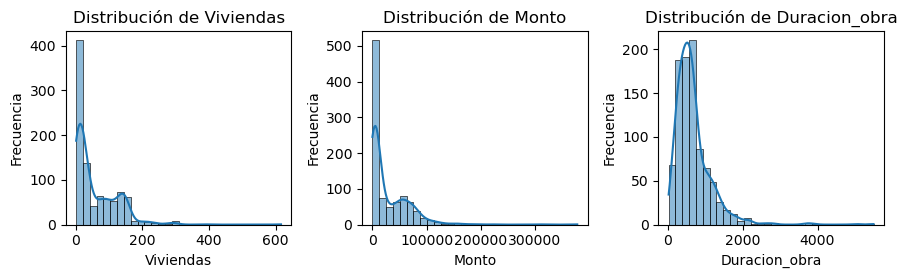

In [39]:
# Visualización de Distribuciones de Variables Numéricas
plt.figure(figsize=(12, 10))
for i, var in enumerate(numeric_vars):
    plt.subplot(4, 4, i + 1)
    sns.histplot(trazabilidad[var], bins=30, kde=True)
    plt.title(f'Distribución de {var}')
    plt.xlabel(var)
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

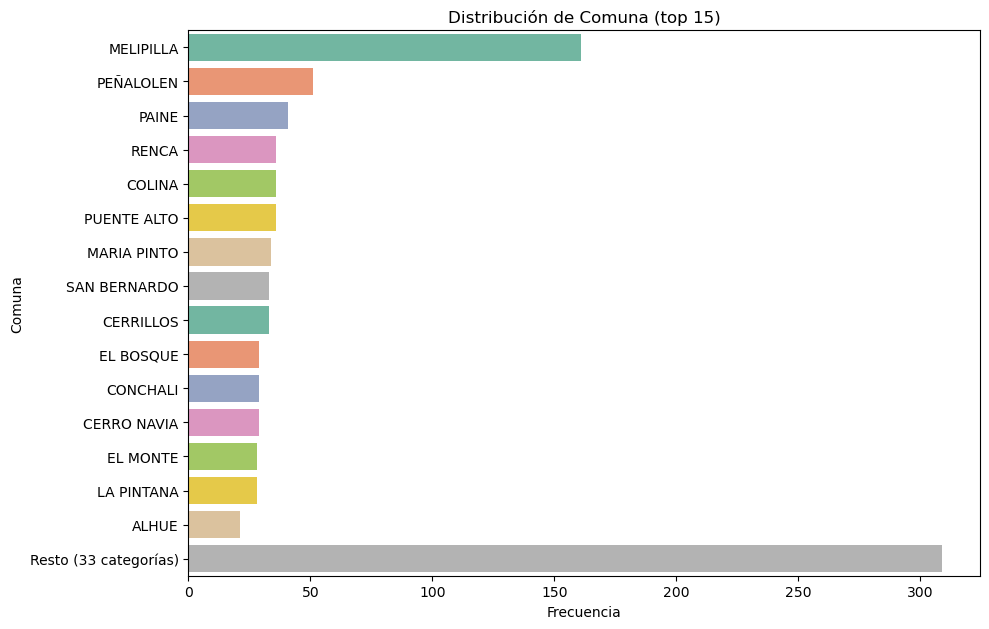

Comuna: 48 categorías
Comuna
MELIPILLA       0.172
PEÑALOLEN       0.055
PAINE           0.044
PUENTE ALTO     0.039
COLINA          0.039
RENCA           0.039
MARIA PINTO     0.036
CERRILLOS       0.035
SAN BERNARDO    0.035
CERRO NAVIA     0.031
CONCHALI        0.031
EL BOSQUE       0.031
LA PINTANA      0.030
EL MONTE        0.030
ALHUE           0.022
Name: proportion, dtype: float64 



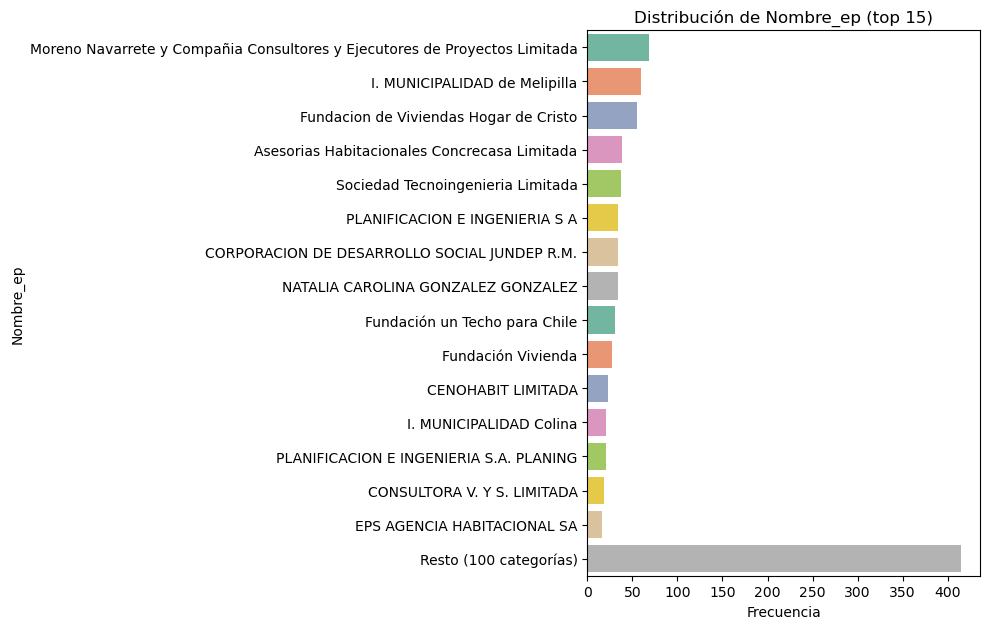

Nombre_ep: 115 categorías
Nombre_ep
Moreno Navarrete y Compañia Consultores y Ejecutores de Proyectos Limitada    0.073
I. MUNICIPALIDAD de Melipilla                                                 0.064
Fundacion de Viviendas Hogar de Cristo                                        0.059
Asesorias Habitacionales Concrecasa Limitada                                  0.042
Sociedad Tecnoingenieria Limitada                                             0.040
PLANIFICACION E INGENIERIA S A                                                0.036
NATALIA CAROLINA GONZALEZ GONZALEZ                                            0.036
CORPORACION DE DESARROLLO SOCIAL JUNDEP R.M.                                  0.036
Fundación un Techo para Chile                                                 0.033
Fundación Vivienda                                                            0.029
CENOHABIT LIMITADA                                                            0.025
I. MUNICIPALIDAD Colina                 

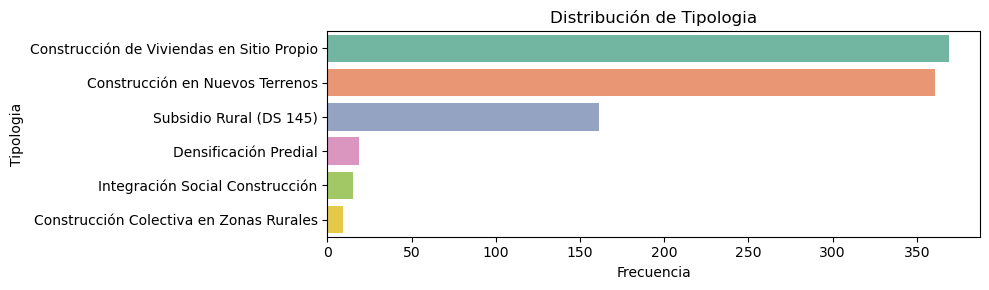

Tipologia: 6 categorías
Tipologia
Construcción de Viviendas en Sitio Propio    0.395
Construcción en Nuevos Terrenos              0.387
Subsidio Rural (DS 145)                      0.172
Densificación Predial                        0.020
Integración Social Construcción              0.016
Construcción Colectiva en Zonas Rurales      0.010
Name: proportion, dtype: float64 



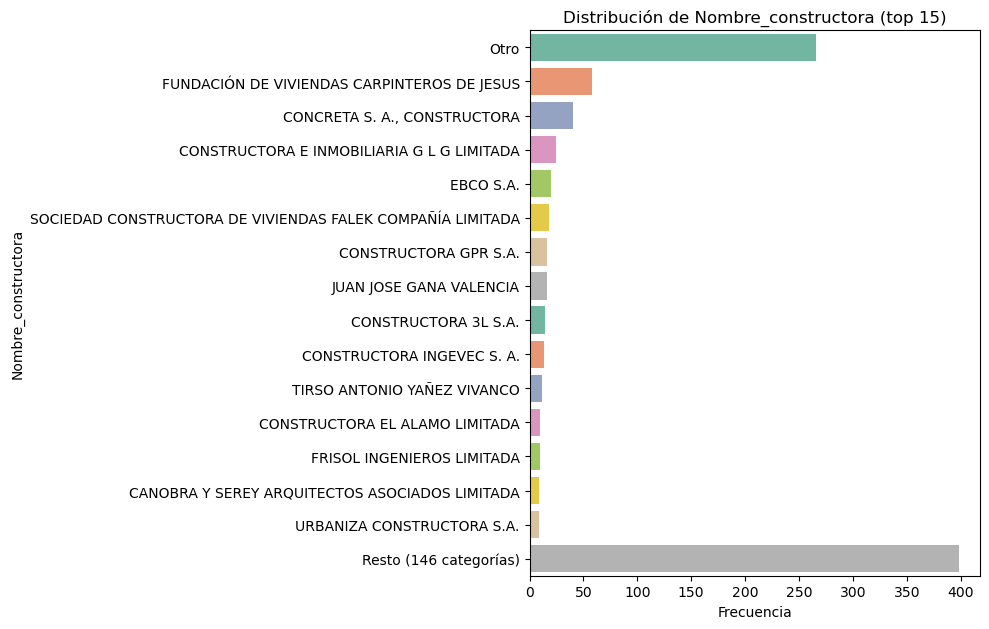

Nombre_constructora: 161 categorías
Nombre_constructora
Otro                                                          0.285
FUNDACIÓN DE VIVIENDAS CARPINTEROS DE JESUS                   0.062
CONCRETA S. A., CONSTRUCTORA                                  0.043
CONSTRUCTORA E INMOBILIARIA G L G LIMITADA                    0.027
EBCO S.A.                                                     0.021
SOCIEDAD CONSTRUCTORA DE VIVIENDAS FALEK COMPAÑÍA LIMITADA    0.019
CONSTRUCTORA GPR S.A.                                         0.017
JUAN JOSE GANA VALENCIA                                       0.017
CONSTRUCTORA 3L S.A.                                          0.015
CONSTRUCTORA INGEVEC S. A.                                    0.014
TIRSO ANTONIO YAÑEZ VIVANCO                                   0.013
CONSTRUCTORA EL ALAMO LIMITADA                                0.011
FRISOL INGENIEROS LIMITADA                                    0.011
CANOBRA Y SEREY ARQUITECTOS ASOCIADOS LIMITADA              

In [40]:
# Análisis de Variables Categóricas
TOP_N = 15

for var in categorical_vars:
    conteo = trazabilidad[var].astype(str).value_counts()

    # Si hay muchas categorías, se muestran las TOP_N y el resto se agrupa
    if len(conteo) > TOP_N:
        resto = conteo.iloc[TOP_N:].sum()
        conteo = conteo.iloc[:TOP_N]
        conteo[f"Resto ({len(trazabilidad[var].unique()) - TOP_N} categorías)"] = resto

    alto = max(3, 0.4 * len(conteo))          # el alto crece con la cantidad de barras
    plt.figure(figsize=(10, alto))
    sns.barplot(x=conteo.values, y=conteo.index, palette="Set2")
    plt.title(f"Distribución de {var} (top {TOP_N})" if len(conteo) > TOP_N else f"Distribución de {var}")
    plt.xlabel("Frecuencia")
    plt.ylabel(var)
    plt.tight_layout()
    plt.show()

    # Resumen estadístico
    print(f"{var}: {trazabilidad[var].nunique()} categorías")
    print(trazabilidad[var].value_counts(normalize=True).head(TOP_N).round(3), "\n")

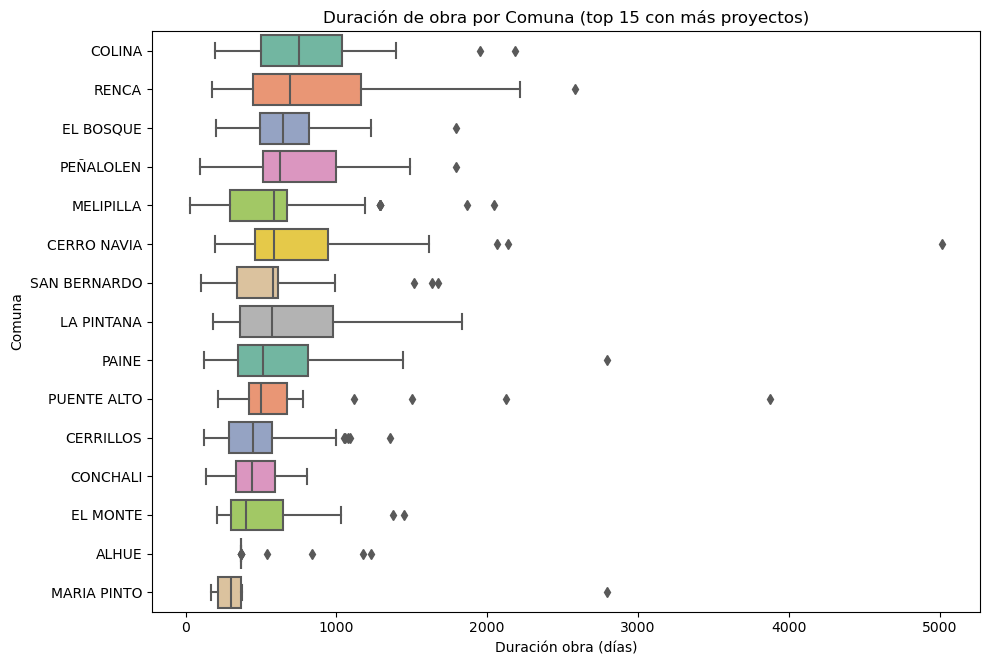

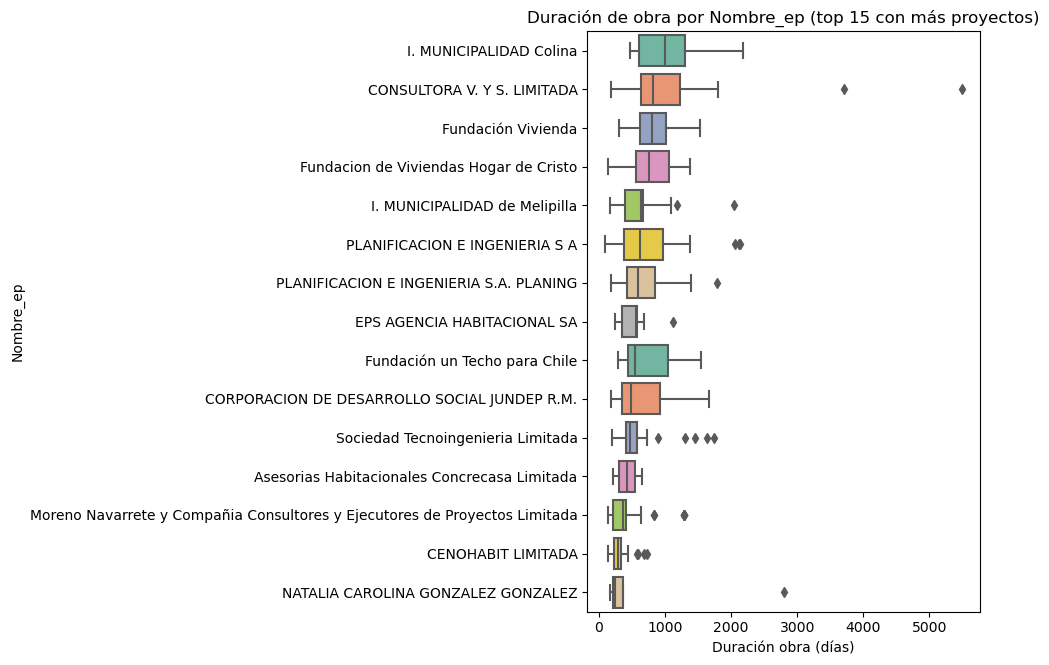

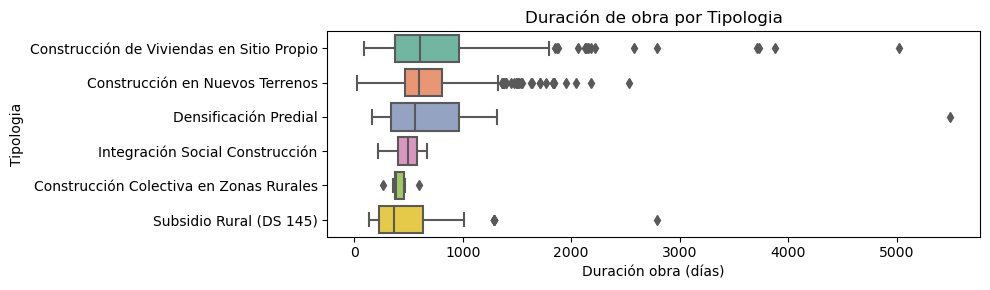

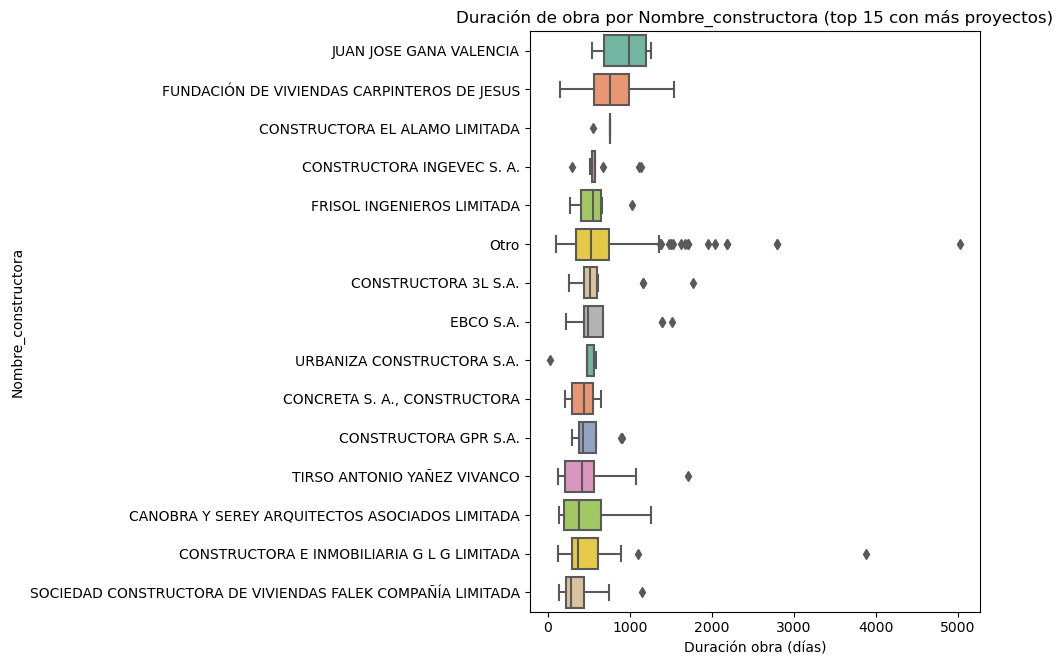

In [41]:
# Comparación de Duracion Obra con Variables Categóricas
TOP_N = 15

for var in categorical_vars:
    datos = trazabilidad[[var, "Duracion_obra"]].copy()
    datos[var] = datos[var].astype(str)
    datos["Duracion_obra"] = datos["Duracion_obra"].astype(float)

    # Solo las TOP_N categorías con más proyectos
    top = datos[var].value_counts().index[:TOP_N]
    datos = datos[datos[var].isin(top)]

    # Orden de mayor a menor mediana de duración
    orden = datos.groupby(var)["Duracion_obra"].median().sort_values(ascending=False).index

    alto = max(3, 0.45 * len(orden))
    plt.figure(figsize=(10, alto))
    sns.boxplot(data=datos, x="Duracion_obra", y=var, order=orden, palette="Set2")
    plt.title(f"Duración de obra por {var}" + (f" (top {TOP_N} con más proyectos)" if trazabilidad[var].nunique() > TOP_N else ""))
    plt.xlabel("Duración obra (días)")
    plt.ylabel(var)
    plt.tight_layout()
    plt.show()

Las cuatros variables muestran una mediana de duración que varia hasta 2 a 3 veces entre categoría, por otro lado:

<br>Tipología
* Las medianas son parecidas (unos 400 a 600 días). Esta variable explica más la dispersión que el nivel.
* Sitio Propio y Nuevos Terrenos concentran casi todos los outliers. Densificación Predial tiene el rango intercuartil más ancho.
* Las tipologías rurales (Colectiva Rural, DS 145) e Integración Social son más cortas y homogéneas.

<br>Entidad Patrocinante (EP)

* Las municipalidades y fundaciones (Colina, Hogar de Cristo, Fundación Vivienda) andan cerca de 700 a 1.000 días, y las consultoras privadas chicas (Cenohabit, Moreno Navarrete) cerca de 250 a 400.
* Puede que la EP no cause el retraso, sino que refleje qué tipo de proyecto toma cada una (por ejemplo, las fundaciones trabajan con sitio propio y familias vulnerables).

<br>Constructora

* Las medianas van de unos 350 días (Falek) a unos 1.000 (Juan José Gana).
* Varias cajas son casi una línea (El Álamo, Ingevec, Urbaniza), lo que indica muy pocos proyectos. Ahí el efecto estimado no es confiable.
* "Otro" agrupa la mayoría de los outliers extremos.

<br>Comuna

* Colina y Renca son las más largas (mediana de unos 700 a 750 días). Las rurales (María Pinto, Alhué, El Monte) son más cortas.
* Esto se solapa con la tipología rural y con la EP: la Municipalidad de Colina y la comuna de Colina son casi la misma información.

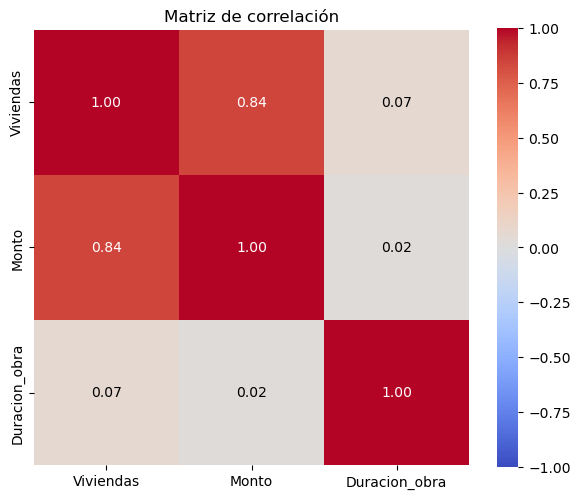

In [42]:
plt.figure(figsize=(6, 5))
correlation_matrix = trazabilidad[numeric_vars].astype(float).corr()

ax = sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm",
                 vmin=-1, vmax=1, square=True)

for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix.columns)):
        valor = correlation_matrix.iloc[i, j]
        ax.text(j + 0.5, i + 0.5, f"{valor:.2f}", ha="center", va="center",
                color="white" if abs(valor) > 0.5 else "black")

plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\ggalvezb\AppData\Local\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


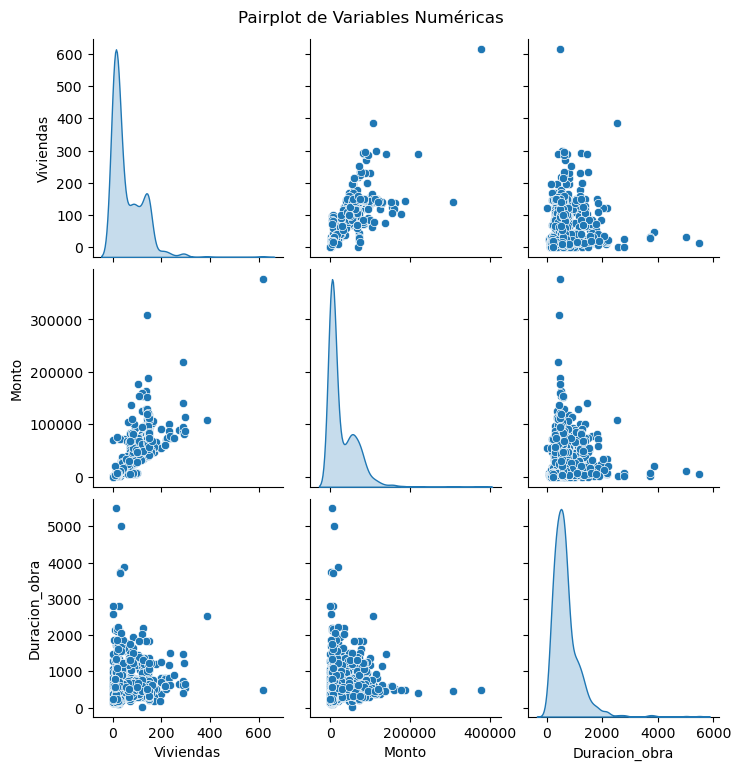

In [43]:
# Análisis Bivariado - Gráfico Pairplot
sns.pairplot(trazabilidad[numeric_vars], diag_kind='kde', markers='o')
plt.suptitle('Pairplot de Variables Numéricas', y=1.02)
plt.show()

Este análisis de correlación indica que la variable objetivo "Duración Obra" casi no tiene una correlación con las variables Viviendas y Monto. Esto es preocupante para el modelo, pero de todas formas se hará una versión 1 incluyendo estas variables.

# Selección de Variables y Modelo

In [44]:
# Dividimos los datos en conjunto de entrenamiento y prueba
y = trazabilidad['Duracion_obra']
X = trazabilidad.drop(columns=["Duracion_obra", "Codigo_proyecto","Ano_llamado","Nombre_proyecto"])


In [45]:
def agrupar(s, min_n=20):
    s = s.astype(str)
    c = s.value_counts()
    return s.where(s.map(c) >= min_n, "OTRAS").astype("category")

X["Nombre_constructora"] = X["Nombre_constructora"].str.strip()
X.loc[X["Nombre_constructora"].str.upper().isin(["OTRO", "OTRAS"]), "Nombre_constructora"] = "OTRAS"

for col in ["Comuna", "Nombre_ep", "Nombre_constructora"]:
    X[col] = agrupar(X[col])

X["log_monto"] = np.log(X["Monto"])
X["log_viviendas"] = np.log(X["Viviendas"])
X = X.drop(columns=["Monto", "Viviendas"])

X = pd.get_dummies(X, drop_first=True, dtype=int)

In [46]:
X

,log_monto,log_viviendas,Comuna_CERRILLOS,Comuna_CERRO NAVIA,Comuna_COLINA,Comuna_CONCHALI,Comuna_EL BOSQUE,Comuna_EL MONTE,Comuna_LA PINTANA,Comuna_LAMPA,...,Nombre_ep_Sociedad Tecnoingenieria Limitada,Tipologia_Construcción de Viviendas en Sitio Propio,Tipologia_Construcción en Nuevos Terrenos,Tipologia_Densificación Predial,Tipologia_Integración Social Construcción,Tipologia_Subsidio Rural (DS 145),Nombre_constructora_CONSTRUCTORA E INMOBILIARIA G L G LIMITADA,Nombre_constructora_EBCO S.A.,Nombre_constructora_FUNDACIÓN DE VIVIENDAS CARPINTEROS DE JESUS,Nombre_constructora_OTRAS
0,8.884610,2.944439,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
1,10.951613,4.70048,0,0,0,0,0,0,0,0,...,1,0,1,0,0,0,0,0,0,1
2,9.340052,3.496508,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,1,0,0,0
3,10.328755,3.583519,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
4,10.434116,3.688879,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
929,10.747894,4.60517,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
930,11.114863,4.219508,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
931,11.314560,4.430817,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
932,11.130030,4.248495,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1


In [47]:
# Nos aseguramos de que no haya valores nulos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [48]:
# Lista de modelos a evaluar
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),

}

# Evaluar el rendimiento de los modelos utilizando validación cruzada
results = {}
for name, model in models.items():
    pipeline = Pipeline([('scaler', StandardScaler()), ('model', model)])
    scores = cross_val_score(pipeline, X, y, cv=5, scoring='neg_mean_squared_error')
    mse_scores = -scores.mean()
    results[name] = mse_scores
    print(f"{name}: MSE = {mse_scores:.4f}")

Linear Regression: MSE = 247799433368182111717862408192.0000
Ridge: MSE = 237225.9813
Random Forest: MSE = 265833.6034
Gradient Boosting: MSE = 248095.2432
Support Vector Machine: MSE = 254008.5176


In [50]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error, max_error
# Entreno Ridge (con el mismo escalado que en la validación cruzada)
ridge = Pipeline([("scaler", StandardScaler()), ("model", models["Ridge"])])
ridge.fit(X_train, y_train)

# Obtengo métricas de Ridge
y_pred = ridge.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.1f} días")
print(f"R²:   {r2:.3f}")

RMSE: 394.9 días
R²:   -0.079


In [49]:
models.items()

dict_items([('Linear Regression', LinearRegression()), ('Ridge', Ridge()), ('Random Forest', RandomForestRegressor(random_state=42)), ('Gradient Boosting', GradientBoostingRegressor(random_state=42)), ('Support Vector Machine', SVR())])